# Dateiimport: ein Beispiel

Wir lesen die drei Dateitypen eines Experiments und sehen uns das Ergebnis an.
Die Rohdaten werden nicht verändert. Zeitstempel sind in Millisekunden.

Das Notebook im Ordner `notebooks` oder im Projektordner starten.
Benötigt werden die Pakete aus `requirements.txt`.


In [1]:
from pathlib import Path
import sys

project = Path.cwd()
if project.name == "notebooks":
    project = project.parent

sys.path.insert(0, str(project))
from src.spectral_sensor.io import read_sensor_csv, read_marker_rows, read_protocol

data = project / "experiments/E02_20x15_mag_steering/data"
sensor_files = {
    "sensor_1": data / "SpectralSensor 1_20260708_113243.csv",
    "sensor_2": data / "SpectralSensor 2_20260708_113243.csv",
    "sensor_3": data / "SpectralSensor 3_20260708_113243.csv",
}
marker_file = data / "Markers_20260708_113243.csv"
protocol_file = data / "Protocol.md"


## Sensorwerte

Jede Zeile ist ein Messpunkt. Die Spaltennamen und Werte bleiben wie in der CSV.


In [2]:
sensor_data = {}

for sensor_name, path in sensor_files.items():
   sensor_data[sensor_name]= read_sensor_csv(path)

sensor_data["sensor_2"].head(2)


,sensor,timestamp,405,425,450,475,515,550,555,600,640,690,745,800,855
0,1001,11406490,2193,2631,3326,3234,3800,4777,6173,6272,6998,1850,3050,6607,2794
1,1001,11406566,2197,2636,3326,3240,3807,4785,6174,6274,7010,1853,3055,6618,2809


In [3]:
for sensor_name, table in sensor_data.items():
    print(sensor_name)
    print(f"Messpunkte: {len(table)}")
    print(f"Spalten: {table.columns.tolist()}")
    print()

sensor_1
Messpunkte: 36953
Spalten: ['sensor', 'timestamp', '405', '425', '450', '475', '515', '550', '555', '600', '640', '690', '745', '800', '855']

sensor_2
Messpunkte: 37192
Spalten: ['sensor', 'timestamp', '405', '425', '450', '475', '515', '550', '555', '600', '640', '690', '745', '800', '855']

sensor_3
Messpunkte: 37142
Spalten: ['sensor', 'timestamp', '405', '425', '450', '475', '515', '550', '555', '600', '640', '690', '745', '800', '855']



In [4]:
wavelength_nm = 640
selected_data = {}

for sensor_name, table in sensor_data.items():
    selected_data[sensor_name] = table[
        ["timestamp", str(wavelength_nm)]
    ].copy()


selected_data["sensor_1"].head(2)


,timestamp,640
0,11406384,2178
1,11406461,2184


## Marker

Ein Marker enthält einen Zeitstempel und einen Beschreibungstext.
`parse_error` zeigt fehlerhafte Zeilen. Die Bedeutung der Marker wird erst im Analyzer ausgewertet.


In [5]:
markers = read_marker_rows(marker_file)
display(markers.head(30))
markers[["line_number", "label"]].head(3)


,line_number,marker_id,timestamp_raw_ms,label,parse_error
0,1,99,11406248,"STEP_1: Start sensor (upstream, downstream, re...",
1,2,99,11406537,STEP_2: Move robot to C20_full_off @ 1.0,
2,3,99,11409855,STEP_3: Start peristaltic (10.0 ml/min),
3,4,99,11412204,STEP_4: Wait (20 min Sensor warm up),
4,5,99,12652479,STEP_5: Warte auf Continue (prepare 100% ref s...,
5,6,99,12671755,STEP_6: Inject syringe 200.0 ul @ 10.0 ul/min,
6,7,99,12672750,STEP_7: Warte auf Continue (Reference no Magnet),
7,8,99,12862433,STEP_8: Inject syringe 50.0 ul @ 10.0 ul/min,
8,9,99,12956988,STEP_9: Inject syringe 50.0 ul @ 10.0 ul/min,
9,10,99,13052072,STEP_10: Inject syringe 50.0 ul @ 10.0 ul/min,


,line_number,label
0,1,"STEP_1: Start sensor (upstream, downstream, re..."
1,2,STEP_2: Move robot to C20_full_off @ 1.0
2,3,STEP_3: Start peristaltic (10.0 ml/min)


## Protokoll

Diese Angaben beschreiben das Experiment und die Herkunft der Messung.


In [6]:
metadata = read_protocol(protocol_file)
metadata.get("experiment_name")


'E02_C20x15_50%_static_test'

# 2. Preprozessing

In [7]:
# Frühester Zeitstempel aller Sensoren und Marker
start_times = [
    table["timestamp"].min()
    for table in sensor_data.values()
]
start_times.append(markers["timestamp_raw_ms"].min())

start_ms = min(start_times)

# Gemeinsame Zeitachse in Sekunden
for table in selected_data.values():
    table["time_s"] = (table["timestamp"] - start_ms) / 1000

prepared_markers = markers.copy()
prepared_markers["time_s"] = (
    prepared_markers["timestamp_raw_ms"] - start_ms
) / 1000

display(selected_data["sensor_1"].head())
display(prepared_markers.head())

,timestamp,640,time_s
0,11406384,2178,0.136
1,11406461,2184,0.213
2,11406537,2185,0.289
3,11406613,2185,0.365
4,11406689,2183,0.441


,line_number,marker_id,timestamp_raw_ms,label,parse_error,time_s
0,1,99,11406248,"STEP_1: Start sensor (upstream, downstream, re...",,0.000
1,2,99,11406537,STEP_2: Move robot to C20_full_off @ 1.0,,0.289
2,3,99,11409855,STEP_3: Start peristaltic (10.0 ml/min),,3.607
3,4,99,11412204,STEP_4: Wait (20 min Sensor warm up),,5.956
4,5,99,12652479,STEP_5: Warte auf Continue (prepare 100% ref s...,,1246.231


### Als fertiger import aus src lib

In [8]:
from src.spectral_sensor.preprocessing import synchronize_time, select_time_window

synced_sensors, synced_markers, start_ms = synchronize_time(
    sensor_data,
    markers,
)

synced_sensors["sensor_1"].head()

,sensor,timestamp,405,425,450,475,515,550,555,600,640,690,745,800,855,time_s
0,1000,11406384,746,866,986,1061,1288,1534,1908,1964,2178,670,796,2346,1523,0.136
1,1000,11406461,749,870,985,1065,1292,1540,1907,1963,2184,673,799,2354,1541,0.213
2,1000,11406537,749,870,988,1065,1292,1540,1911,1967,2185,672,799,2354,1611,0.289
3,1000,11406613,749,870,988,1064,1293,1540,1912,1968,2185,673,799,2354,1537,0.365
4,1000,11406689,749,870,988,1064,1292,1541,1913,1968,2183,673,800,2354,1544,0.441


### Signale Ausschneiden

In [9]:


preroll_s = 0.0 #seconds
window_s = 50.0 #seconds

sensor_clipped = select_time_window(synced_sensors, preroll_s, window_s)

sensor_clipped["sensor_1"]["time_s"].agg(["min", "max", "count"])

min        0.136
max       49.931
count    655.000
Name: time_s, dtype: float64

In [10]:
synced_markers[["time_s", "label"]]

marker_index = 5
start_s = synced_markers.loc[marker_index, "time_s"]

sensor_clipped = select_time_window(synced_sensors, start_s, window_s)

sensor_clipped["sensor_1"]["time_s"].agg(["min", "max", "count"])

min      1265.507
max      1315.489
count     657.000
Name: time_s, dtype: float64

In [11]:
import importlib
from src.spectral_sensor import preprocessing

importlib.reload(preprocessing)
from src.spectral_sensor.preprocessing import select_time_window,marker_time

sensor_clipped["sensor_1"][
    ["time_s", "time_from_start_s", str(wavelength_nm)]
].head()

,time_s,time_from_start_s,640
16609,1265.507,0.000,5466
16610,1265.583,0.076,5467
16611,1265.660,0.153,5465
16612,1265.736,0.229,5463
16613,1265.812,0.305,5465


# 3. Plotting

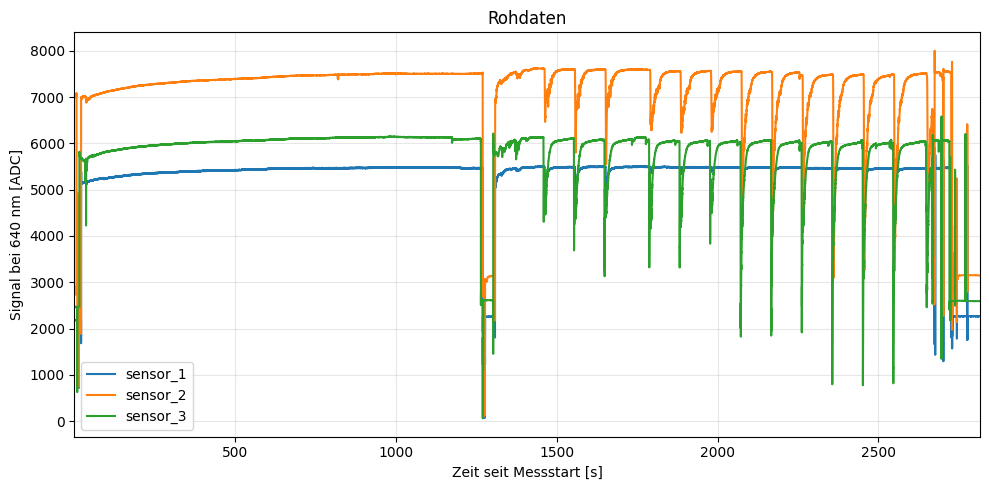

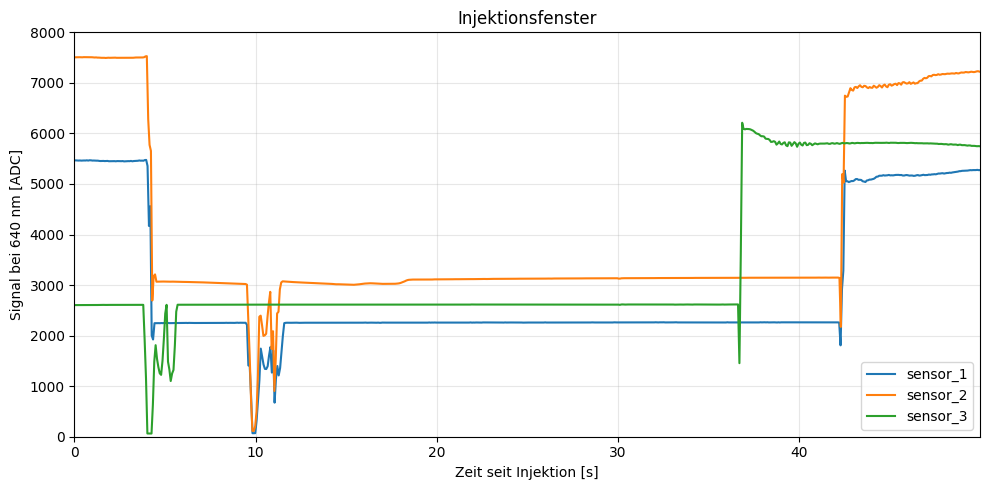

In [12]:
from src.spectral_sensor.plotting import plot_timeseries

fig, ax = plot_timeseries(
    synced_sensors,
    time_column="time_s",
    signal_column=str(wavelength_nm),
    xlabel="Zeit seit Messstart [s]",
    ylabel=f"Signal bei {wavelength_nm} nm [ADC]",
    title="Rohdaten",
)
Step_6 = sensor_clipped["sensor_1"]["time_from_start_s"]
fig, ax = plot_timeseries(
    sensor_clipped,
    time_column="time_from_start_s",
    signal_column=str(wavelength_nm),
    xlabel="Zeit seit Injektion [s]",
    ylabel=f"Signal bei {wavelength_nm} nm [ADC]",
    title="Injektionsfenster",
)
ax.set_ylim(0, 8000)
fig.savefig("rohdaten.png", dpi=300)

(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Injektionsfenster'}, xlabel='Zeit seit Injektion [s]', ylabel='Signal bei 640 nm [ADC]'>)

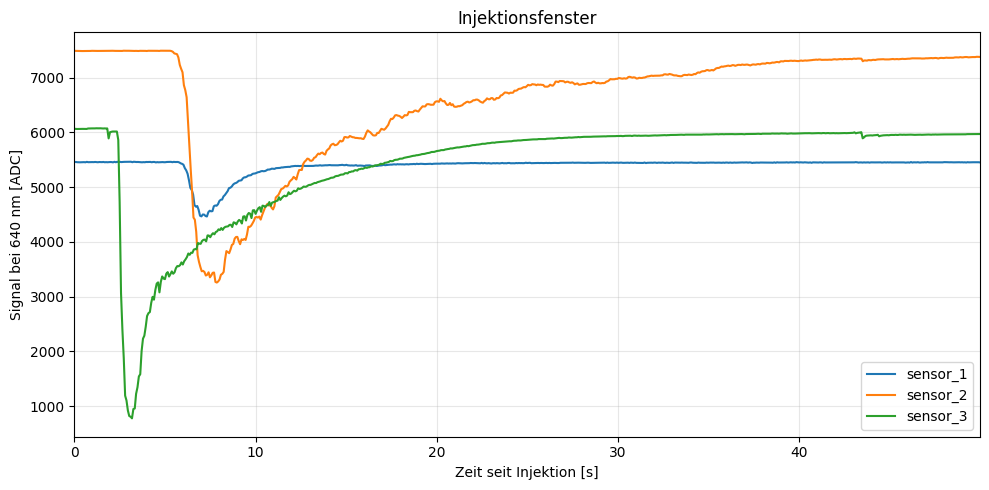

In [13]:
start_s = marker_time(synced_markers, marker_num=19)

window_sensors = select_time_window(
    synced_sensors,
    start_s=start_s,
    window_s=window_s,
)

plot_timeseries(
    window_sensors,
    time_column="time_from_start_s",
    signal_column=str(wavelength_nm),
    xlabel="Zeit seit Injektion [s]",
    ylabel=f"Signal bei {wavelength_nm} nm [ADC]",
    title="Injektionsfenster",
)

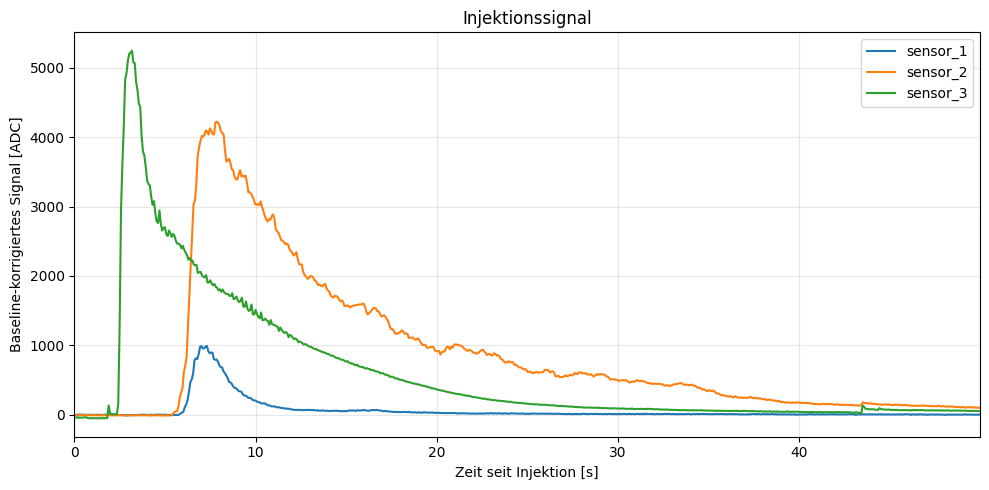

In [14]:
baseline_window_s = 10
from src.spectral_sensor.normalization import baseline_correction, get_min, normalize_signal

corrected_sensors = baseline_correction(
    synced_sensors,
    window_sensors,
    wavelength_nm=wavelength_nm,
    start_s=start_s,
    baseline_window_s=baseline_window_s,
)

fig, ax = plot_timeseries(
    corrected_sensors,
    time_column="time_from_start_s",
    signal_column="absorption_adc",
    xlabel="Zeit seit Injektion [s]",
    ylabel="Baseline-korrigiertes Signal [ADC]",
    title="Injektionssignal",
)

### Normalized Signal

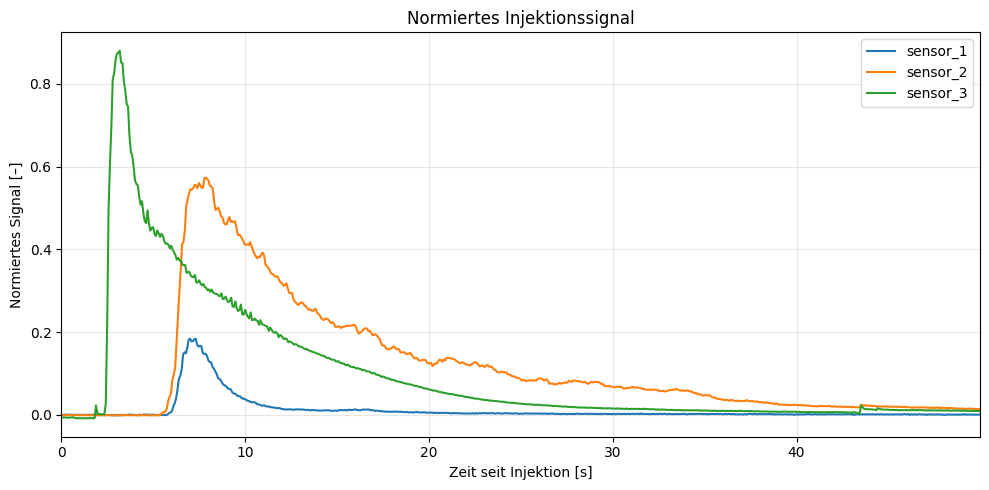

In [15]:
from src.spectral_sensor.normalization import (
    get_min,
    normalize_signal,
)

reference_start_s = marker_time(synced_markers, 6)
reference_end_s = marker_time(synced_markers, 7)

reference_sensors = select_time_window(
    synced_sensors,
    start_s=reference_start_s,
    window_s=reference_end_s - reference_start_s,
)

references = get_min(
    reference_sensors,
    wavelength_nm=wavelength_nm,
)

normalized_sensors = normalize_signal(
    corrected_sensors,
    references,
)
fig, ax = plot_timeseries(
    normalized_sensors,
    time_column="time_from_start_s",
    signal_column="normalized_0_1",
    xlabel="Zeit seit Injektion [s]",
    ylabel="Normiertes Signal [–]",
    title="Normiertes Injektionssignal",
)

# Data Analysis

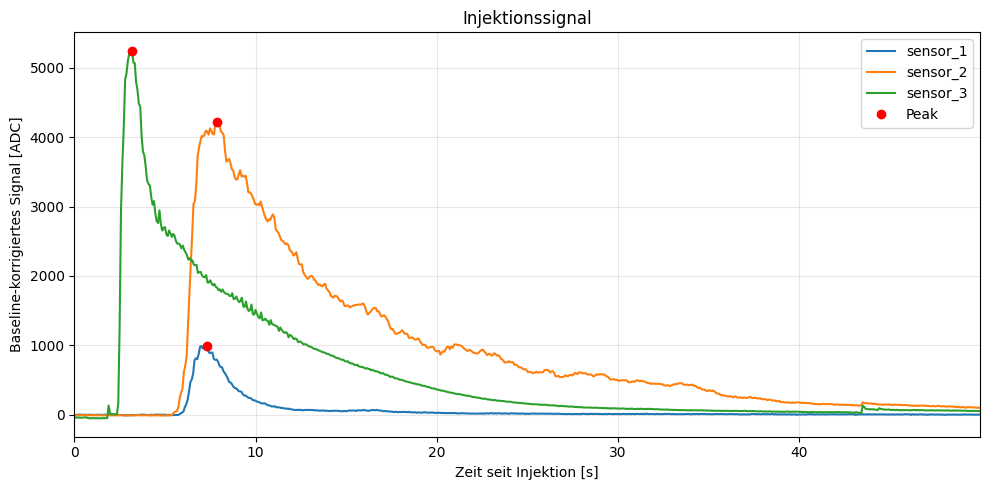

In [16]:

import importlib
from src.spectral_sensor.analysis import get_min, get_peak

peak_results = get_peak(
    corrected_sensors,
    time_column="time_from_start_s",
    signal_column="absorption_adc",
)

peak_results

fig,ax=plot_timeseries(corrected_sensors,
    time_column="time_from_start_s",
    signal_column="absorption_adc",
    xlabel="Zeit seit Injektion [s]",
    ylabel="Baseline-korrigiertes Signal [ADC]",
    title="Injektionssignal")
ax.plot(peak_results["peak_time_s"], peak_results["peak_value"], "ro", label="Peak")
ax.legend()


# Metrics


In [19]:
from src.spectral_sensor.analysis import get_peak, get_integral
from src.spectral_sensor.io import save_results

output_folder = "../results/injection_01"
positive_only = True

integrals = get_integral(
    normalized_sensors,
    time_column="time_from_start_s",
    signal_column="absorption_adc",
    positive_only=positive_only,
)


metrics = peak_results.merge(integrals, on="sensor")

metrics = metrics.rename(columns={
    "peak_value": "peak_absorption_adc",
    "integral": "integral_absorption_adc_s",
})


metrics

save_results(
    normalized_sensors,
    metrics,
    output_folder=output_folder,
)

In [20]:
for sensor_name, table in synced_sensors.items():
    print(sensor_name)
    print("Erster Zeitstempel [ms]:", table["timestamp"].iloc[0])
    print("Beginn seit Messstart [s]:", table["time_s"].iloc[0])
    print()

print("Fensterstart [s]:", start_s)

sensor_1
Erster Zeitstempel [ms]: 11406384
Beginn seit Messstart [s]: 0.136

sensor_2
Erster Zeitstempel [ms]: 11406490
Beginn seit Messstart [s]: 0.242

sensor_3
Erster Zeitstempel [ms]: 11406597
Beginn seit Messstart [s]: 0.349

Fensterstart [s]: 2448.515


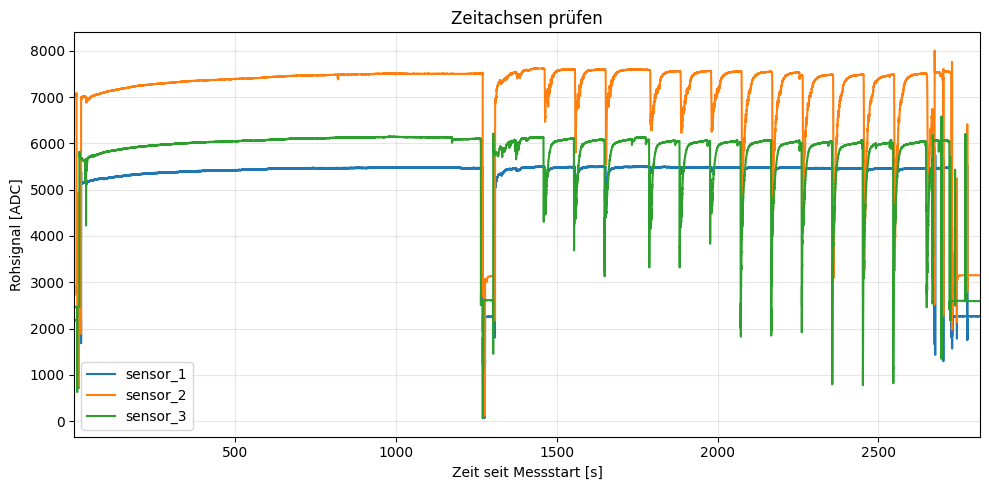

In [21]:
fig, ax = plot_timeseries(
    synced_sensors,
    time_column="time_s",
    signal_column=str(wavelength_nm),
    xlabel="Zeit seit Messstart [s]",
    ylabel="Rohsignal [ADC]",
    title="Zeitachsen prüfen",
)